# Complex analysis 3: Contour integrals

*Learning path: complex analysis, part 3 of 8.* [Index](README.md) · Previous: [Analytic functions](02-analytic-functions.ipynb) · Next: [Cauchy's theorem](04-cauchy.ipynb)

On the real line there is only one way to get from $a$ to $b$. In the plane there are infinitely many, so an integral
from $a$ to $b$ has to say which path it takes. Does the answer depend on the path? For $z^2$ it does not; for $\bar z$
it does; and for $1/z$ the answer around a closed loop is $2\pi i$, a single number that the rest of the course is
built on. This lesson defines the integral along a path and computes it, by hand and with `cint`.

**Who this is for.** You have done [lesson 2](02-analytic-functions.ipynb) and know line integrals and parametrized
curves ([multivariable calculus 6](../multivariable/06-vector-fields-and-line-integrals.ipynb)).

**What you will be able to do afterwards:**

1. parametrize a path $z(t)$ and compute $\int_\gamma f\,dz = \int f(z(t))\,z'(t)\,dt$ by hand and with `cint`;
2. use an antiderivative to evaluate an integral, and see when the path does not matter;
3. compute the fundamental integral $\oint z^n\,dz$ around a circle, and know why $n = -1$ is special;
4. bound an integral with the length times the maximum, the estimate behind every trick in lesson 7.

Plan about an hour.

## 1. Integrating along a path

A **path** is a curve $z(t)$, $a \le t \le b$, in the complex plane. The integral of $f$ along it is defined by
substituting the path:

$$\int_\gamma f(z)\,dz = \int_a^b f(z(t))\,z'(t)\,dt.$$

Take $f(z) = z^2$ from $0$ to $1 + i$ along two paths: the straight line $z = t + it$ and the parabola $z = t + it^2$.

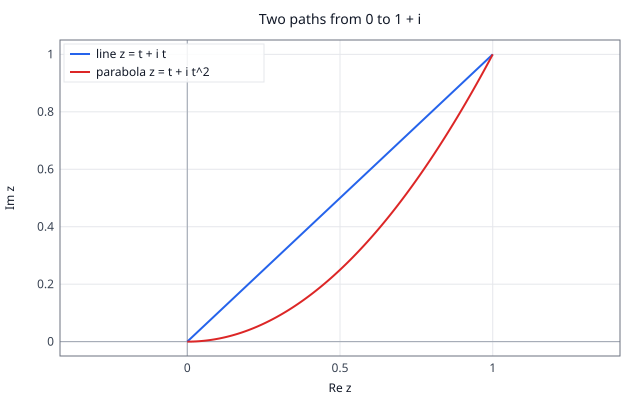

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
p = parametric(t, t, t, 0, 1);
p = show(p, parametric(t, t^2, t, 0, 1));
p = legend(p, "line z = t + i t", "parabola z = t + i t^2");
labels(title(p, "Two paths from 0 to 1 + i"), "Re z", "Im z")

Along the parabola $z' = 1 + 2it$, and the integral becomes an ordinary one in $t$:

In [2]:
integrate((t + i*t^2)^2*(1 + 2*i*t), t, 0, 1)

-2/3+2*i/3

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

`cint(f, z, path, t, t0, t1)` does the same substitution numerically, for any path:

In [3]:
cint(z^2, z, t + i*t^2, t, 0, 1)
cint(z^2, z, t + i*t, t, 0, 1)

-0.666666666667+0.666666666667*i

> Contour integral of f dz along z = t+i*t^2, t from 0 to 1: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

-0.666666666667+0.666666666667*i

> Contour integral of f dz along z = t+i*t, t from 0 to 1: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

Both paths give $-\tfrac23 + \tfrac23 i$. (`cint` returns decimals, rounded to 12 digits; the exact values come from
`integrate`.)

**Try this.** Compute $\int z^2\,dz$ along a third path, $z = t^3 + it$ for $0 \le t \le 1$, by hand with `integrate`
and with `cint`.

## 2. Antiderivatives: when the path does not matter

The answer above is no coincidence. If $F' = f$ on a region containing the path, the chain rule gives
$\frac{d}{dt}F(z(t)) = f(z(t))\,z'(t)$, so

$$\int_\gamma f\,dz = F(\text{end}) - F(\text{start}),$$

whatever the path. For $z^2$, $F = z^3/3$:

In [4]:
expand((1 + i)^3/3)

-2/3+2*i/3

> `expand`: Multiplies out products and powers.

Now try $\bar z$, which has no complex derivative ([lesson 2](02-analytic-functions.ipynb)) and, as it turns out, no
antiderivative either:

In [5]:
cint(conj(z), z, t + i*t, t, 0, 1)
cint(conj(z), z, t + i*t^2, t, 0, 1)

1.0

> Contour integral of f dz along z = t+i*t, t from 0 to 1: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

1.0+0.333333333333*i

> Contour integral of f dz along z = t+i*t^2, t from 0 to 1: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

The two paths give different answers, $1$ and $1 + i/3$. Around a closed loop the difference shows up as a non-zero
integral. For the circle $z = re^{it}$, $\bar z\,dz = re^{-it}\cdot ire^{it}\,dt = ir^2\,dt$, so
$\oint \bar z\,dz = 2\pi i r^2$, which is $2i$ times the enclosed area:

In [6]:
cint(conj(z), z, exp(i*t), t, 0, 2*pi)
cint(conj(z), z, 2*exp(i*t), t, 0, 2*pi)

6.28318530718*i

> Contour integral of f dz along z = exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps. This is 1 × 2πi.

25.1327412287*i

> Contour integral of f dz along z = 2*exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps. This is 4 × 2πi.

$2\pi i$ and $8\pi i$. In general $\oint \bar z\,dz = 2i \times \text{area}$, by Green's theorem.

**Try this.** Integrate $\operatorname{Re} z$ (`real(z)`) from 0 to $1 + i$ along the two paths of section 1. Is it path
independent?

## 3. The most important integral

Go once counterclockwise round the unit circle, $z = e^{it}$, $0 \le t \le 2\pi$, so $dz = ie^{it}\,dt$. For a whole
power $z^n$,

$$\oint z^n\,dz = \int_0^{2\pi} e^{int}\,ie^{it}\,dt = i\int_0^{2\pi} e^{i(n + 1)t}\,dt,$$

which is 0 unless $n + 1 = 0$, when the integrand is 1 and the answer is $2\pi i$:

In [7]:
cint(z^2, z, exp(i*t), t, 0, 2*pi)
cint(1/z^2, z, exp(i*t), t, 0, 2*pi)
cint(1/z, z, exp(i*t), t, 0, 2*pi)

0.0

> Contour integral of f dz along z = exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

0.0

> Contour integral of f dz along z = exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

6.28318530718*i

> Contour integral of f dz along z = exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps. This is 1 × 2πi.

For $n \ne -1$, $z^n$ has the antiderivative $z^{n+1}/(n+1)$, and a closed loop ends where it starts. For $n = -1$ the
antiderivative would be $\log z$, and $\log z$ is not single valued ([lesson 1](01-complex-functions.ipynb)): going once
round the origin adds $2\pi i$ to it. The answer does not depend on the size or shape of the loop, only on how often it
winds around 0:

In [8]:
cint(1/z, z, 3*exp(i*t), t, 0, 2*pi)
cint(1/z, z, cos(t) + 2*i*sin(t), t, 0, 2*pi)
cint(1/z, z, exp(i*t), t, 0, 4*pi)
cint(1/z, z, exp(-i*t), t, 0, 2*pi)
cint(1/z, z, 2 + exp(i*t), t, 0, 2*pi)

6.28318530718*i

> Contour integral of f dz along z = 3*exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps. This is 1 × 2πi.

6.28318530718*i

> Contour integral of f dz along z = cos(t)+2*i*sin(t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps. This is 1 × 2πi.

12.5663706144*i

> Contour integral of f dz along z = exp(i*t), t from 0 to 4*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps. This is 2 × 2πi.

-6.28318530718*i

> Contour integral of f dz along z = exp(-i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps. This is -1 × 2πi.

0.0

> Contour integral of f dz along z = 2+exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

A circle of radius 3 and an ellipse give $2\pi i$; going round twice gives $4\pi i$; clockwise gives $-2\pi i$; and a
circle around 2, which does not enclose the origin, gives 0. The integral **counts windings**. Half a turn gives half:

In [9]:
cint(1/z, z, exp(i*t), t, 0, pi)

3.14159265359*i

> Contour integral of f dz along z = exp(i*t), t from 0 to pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

which is $\log(-1) - \log 1 = \pi i$ on a branch of the logarithm that is continuous along the upper half circle.

**Try this.** Compute $\oint \dfrac{dz}{z - 1}$ around the circle $|z - 1| = 1$ (path `1 + exp(i*t)`), and around
$|z| = \tfrac12$. Explain both answers.

## 4. Bounding an integral

Often you do not need the value of an integral, only that it is small. If $|f| \le M$ on a path of length $L$, then

$$\left|\int_\gamma f\,dz\right| \le M L.$$

This **ML estimate** is behind every computation of real integrals in [lesson 7](07-real-integrals.ipynb). Take
$f = 1/(z^2 + 1)$ on the upper half circle of radius $R$. Its length is $\pi R$, and on it
$|z^2 + 1| \ge R^2 - 1$, so the integral is at most $\pi R/(R^2 - 1)$, which tends to 0:

In [10]:
cint(1/(z^2 + 1), z, 10*exp(i*t), t, 0, pi)
eval(pi*10/(10^2 - 1))
cint(1/(z^2 + 1), z, 100*exp(i*t), t, 0, pi)
eval(pi*100/(100^2 - 1))

0.199337304982

> Contour integral of f dz along z = 10*exp(i*t), t from 0 to pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

0.3173325912716963

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.0199993333733

> Contour integral of f dz along z = 100*exp(i*t), t from 0 to pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

0.031419068442742205

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Both values sit under their bounds and shrink like $1/R$.

**Try this.** Bound $\int e^{iz}/(z^2 + 1)\,dz$ on the same half circle. (Hint: $|e^{iz}| = e^{-\operatorname{Im} z} \le 1$
in the upper half plane.)

## Summary

* $\int_\gamma f\,dz = \int_a^b f(z(t))\,z'(t)\,dt$; `cint(f, z, path, t, t0, t1)` computes it numerically.
* If $F' = f$ along the path, the integral is $F(\text{end}) - F(\text{start})$, independent of the path; around a closed
  loop it is 0. $\bar z$ has no antiderivative, and $\oint \bar z\,dz = 2i \times \text{area}$.
* $\oint z^n\,dz = 0$ for $n \ne -1$, and $\oint dz/z = 2\pi i$ times the number of times the loop winds around 0.
* ML estimate: $|\int_\gamma f\,dz| \le \max|f| \cdot \text{length}$.

Next: [Cauchy's theorem](04-cauchy.ipynb), which says when a closed integral must vanish.

## Exercises

1. **Straight line.** Compute $\int_0^{1+i} e^z\,dz$ along the straight line with `integrate`, and check it against
   $e^{1+i} - 1$.
2. **Around a square.** Integrate $1/z$ around the square with corners $\pm 1 \pm i$, one side at a time with `cint`
   (for example $z = 1 + it$, $-1 \le t \le 1$ for the right side). Add up the four pieces.
3. **Off center.** Show by hand that $\oint dz/(z - a) = 2\pi i$ around any circle centered at $a$.
4. **Area.** Use $\oint \bar z\,dz = 2i \times \text{area}$ to find the area of the ellipse $z = 3\cos t + 2i\sin t$.
5. **A bound.** Show that $|\oint dz/(z^4 + 2)| \le 2\pi/(R^3 - 2/R)$ on $|z| = R$, $R > 2^{1/4}$, and check it for
   $R = 3$ with `cint`.

## Hints and answers

* **Section 1, Try this.** `integrate((t^3 + i*t)^2*(3*t^2 + i), t, 0, 1)` and `cint(z^2, z, t^3 + i*t, t, 0, 1)` both
  give $-\tfrac23 + \tfrac23 i$.
* **Section 2, Try this.** No: `cint(real(z), z, t + i*t, t, 0, 1)` gives $\tfrac12 + \tfrac i2$, and along the
  parabola it gives $\tfrac12 + \tfrac23 i$.
* **Section 3, Try this.** $2\pi i$ around $|z - 1| = 1$, which winds once around the singularity at 1. 0 around
  $|z| = \tfrac12$, which does not enclose 1: there $\log(z - 1)$ is single valued.
* **Section 4, Try this.** $|e^{iz}/(z^2 + 1)| \le 1/(R^2 - 1)$, so the integral is at most $\pi R/(R^2 - 1) \to 0$.
* **Exercise 1.** `integrate(exp(t + i*t)*(1 + i), t, 0, 1)`; both are $e\cos 1 - 1 + ie\sin 1$.
* **Exercise 2.** Each side gives $\pi i/2$, for a total of $2\pi i$: the square winds once around 0.
* **Exercise 3.** With $z = a + re^{it}$, $dz/(z - a) = i\,dt$.
* **Exercise 4.** `cint(conj(z), z, 3*cos(t) + 2*i*sin(t), t, 0, 2*pi)` is $12\pi i$, so the area is $6\pi$.
* **Exercise 5.** On $|z| = R$, $|z^4 + 2| \ge R^4 - 2$ and the length is $2\pi R$. For $R = 3$ the integral is 0 (it
  decays like $1/z^4$; lesson 6 explains why it vanishes exactly) and the bound is about 0.239.

## Sources

1. A. L. Cauchy, *Mémoire sur les intégrales définies prises entre des limites imaginaires* (1825).
2. T. Needham, *Visual Complex Analysis*, Oxford University Press (1997), chapter 8.
3. E. M. Stein and R. Shakarchi, *Complex Analysis*, Princeton University Press (2003), chapter 1, section 3.
4. J. W. Brown and R. V. Churchill, *Complex Variables and Applications*, 9th ed., McGraw-Hill (2014), chapter 4.